In [1]:
# Reproducible analysis setup
from itertools import combinations
from pathlib import Path
import os
import re
CACHE_DIR = Path(".cache")
TEMP_DIR = CACHE_DIR / "figures"
TEMP_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(CACHE_DIR / "matplotlib"))

import matplotlib.gridspec as gridspec
import matplotlib.image as mpimg
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
from IPython.display import Image as IPythonImage, display
from PIL import Image
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Patch, Rectangle, Wedge
from matplotlib.ticker import MultipleLocator
from pdfrw import PageMerge, PdfReader as PdfReaderRW, PdfWriter as PdfWriterRW
from scipy.stats import chi2_contingency
from wordcloud import ImageColorGenerator, WordCloud

from utils import (
    FIG6_STOPWORDS,
    FOCUS_GROUPS,
    METHOD_NODE_COLOR_OVERRIDES,
    PREDICTOR_CATEGORY_COLORS,
    PREDICTOR_CATEGORY_ORDER,
    assign_year_group,
    benjamini_hochberg,
    binary_presence_statistics,
    calculate_binary_tfidf,
    create_figure_3,
    load_abbreviation_definitions,
    load_binary_mask,
    method_category_distribution,
    pearson_statistic,
    split_multivalue,
    unique_multivalue,
    validate_analysis_data,
    validate_bh,
)

DATA_DIR = Path("data")
FIGURE_DIR = Path("figure")
INPUT_CSV = DATA_DIR / "paper_summary_manually_checked.csv"
FIGURE_DIR.mkdir(exist_ok=True)

df = pd.read_csv(INPUT_CSV)
for column in ["Title", "Abstract", "Algorithm"]:
    df[column] = df[column].fillna("")
validate_analysis_data(df)
df["Fish_Group_list"] = df["Fish_Group"].apply(unique_multivalue)

if len(df) != 123:
    raise ValueError(f"Expected 123 included papers, found {len(df)}")
if (~df["Fish_Group_list"].map(bool)).any():
    raise ValueError("Every paper must have at least one fishery-resource group")

pd.DataFrame({
    "Check": ["Included papers", "Algorithm labels", "Predictor labels"],
    "Value": [
        len(df),
        len({label for value in df["Algorithm"] for label in split_multivalue(value)}),
        len({label for value in df["Predictor"] for label in split_multivalue(value)}),
    ],
})


,Check,Value
0,Included papers,123
1,Algorithm labels,83
2,Predictor labels,181


In [2]:
# Figure 2: temporal trends, algorithm co-occurrence and XAI/uncertainty
# Compute algorithm frequencies and co-occurrence counts for Figure 2.
TOP_N = 20
# Use the complete curated dataset (source data already define the year range)
df_fig2 = df.copy()
df_fig2['kw_list'] = df_fig2['Algorithm'].apply(unique_multivalue)
df_valid = df_fig2[df_fig2['kw_list'].apply(len) > 0].copy()
all_keywords = [kw for kw_list in df_valid['kw_list'] for kw in kw_list]
kw_freq = (
    pd.Series(all_keywords).value_counts()
    .rename_axis('Algorithm').reset_index(name='Frequency')
    .sort_values(['Frequency', 'Algorithm'], ascending=[False, True], kind='stable')
    .set_index('Algorithm')['Frequency']
)
top_methods = kw_freq.head(TOP_N).index.tolist()
cooc_matrix = pd.DataFrame(0, index=top_methods, columns=top_methods)
for kw_list in df_valid['kw_list']:
    present = [kw for kw in kw_list if kw in top_methods]
    for a, b in combinations(sorted(set(present)), 2):
        cooc_matrix.loc[a, b] += 1
        cooc_matrix.loc[b, a] += 1
for m in top_methods:
    cooc_matrix.loc[m, m] = kw_freq.get(m, 0)

# ======== Build 3-stop coolwarm colormap ========
coolwarm_full = plt.colormaps['coolwarm']
n_segments = 9
indices = [0, (n_segments - 1) // 2, n_segments - 1]
coolwarm_colors = [coolwarm_full(i / (n_segments - 1)) for i in indices]

sci_palette = {
    "non-DL":                   '#{:02X}{:02X}{:02X}'.format(int(coolwarm_colors[0][0]*255), int(coolwarm_colors[0][1]*255), int(coolwarm_colors[0][2]*255)),
    "basic DL":                         '#{:02X}{:02X}{:02X}'.format(int(coolwarm_colors[1][0]*255), int(coolwarm_colors[1][1]*255), int(coolwarm_colors[1][2]*255)),
    "advanced DL":     '#{:02X}{:02X}{:02X}'.format(int(coolwarm_colors[2][0]*255), int(coolwarm_colors[2][1]*255), int(coolwarm_colors[2][2]*255)),
}
CAT_COLORS = sci_palette

# ======== Two-row layout: (a–b) above and the full-width trend panel (c) below ========
fig = plt.figure(figsize=(16, 11.8))
gs = gridspec.GridSpec(
    2, 2, height_ratios=[2.15, 1.0], hspace=0.18, wspace=0.12,
    left=0.08, right=0.96, bottom=0.07, top=0.95,
)
ax0 = fig.add_subplot(gs[0, 0], projection='polar')
ax1 = fig.add_subplot(gs[0, 1])
ax2 = fig.add_subplot(gs[1, :])

# ======== (A) Radial chart ========
df_radial = df.copy()
df_radial = df_radial.dropna(subset=['Year', 'LM_Category']).copy()
pivot = df_radial.groupby(['Year', 'LM_Category']).size().unstack(fill_value=0)
all_years_radial = list(range(int(df_radial['Year'].min()), int(df_radial['Year'].max()) + 1))
pivot = pivot.reindex(all_years_radial, fill_value=0)
categories = [c for c in ["non-DL", "basic DL", "advanced DL"] if c in pivot.columns]

ax0.set_theta_offset(np.pi / 2)
ax0.set_theta_direction(-1)

N = len(all_years_radial)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
bar_width = 2 * np.pi / N * 0.85

year_totals = pivot.sum(axis=1).values
max_total = year_totals.max()
inner_radius = max_total * 0.62

bottom = np.zeros(N) + inner_radius
for cat in categories:
    values = pivot[cat].values
    ax0.bar(angles, values, width=bar_width, bottom=bottom,
            color=sci_palette[cat], edgecolor='white', linewidth=0.8,
            alpha=0.9)
    bottom += values

ax0.set_ylim(0, inner_radius + max_total * 1.05)
ax0.set_xticklabels([])
ax0.set_yticklabels([])
ax0.yaxis.grid(False)
ax0.xaxis.grid(False)
ax0.spines['polar'].set_visible(False)

for i, yr in enumerate(all_years_radial):
    angle = angles[i]
    r_label = inner_radius * 0.85
    rotation = -np.degrees(angle)
    ax0.text(angle, r_label, str(yr), ha='center', va='center',
             fontsize=13, fontweight='normal', color='#333333',
             rotation=rotation)
    if yr == 2026:
        ax0.text(angle, r_label - inner_radius * 0.17, 'May',
                 ha='center', va='center', fontsize=11, fontweight='normal',
                 color='#333333', rotation=rotation)

# Panel labels use a shared figure-level y coordinate for exact alignment.
panel_label_y = 0.965
fig.text(0.035, panel_label_y, '(a)',
         fontsize=22, fontweight='bold', va='top', ha='left')

# ======== (B) Network graph ========
method_cat_dist = method_category_distribution(
    top_methods, df_fig2, algorithms_column='kw_list'
)

G = nx.Graph()
for m in top_methods:
    G.add_node(m, weight=kw_freq[m])

for i, a in enumerate(top_methods):
    for b in top_methods[i+1:]:
        w = cooc_matrix.loc[a, b]
        if w >= 1:
            G.add_edge(a, b, weight=w)

isolated = [n for n, d in G.degree() if d == 0]
G.remove_nodes_from(isolated)

pos = nx.spring_layout(G, k=7.0, iterations=50, seed=42, weight='weight')

edge_widths = [G[u][v]['weight'] * 1.2 for u, v in G.edges()]
edge_alphas = [min(G[u][v]['weight'] / 8, 1.0) for u, v in G.edges()]

nx.draw_networkx_edges(G, pos, width=edge_widths, alpha=edge_alphas, edge_color='#888888', ax=ax1)

for node in G.nodes():
    x, y = pos[node]
    dist = method_cat_dist[node]
    total = sum(dist.values())
    radius = np.sqrt(kw_freq[node] * 0.75) / 42

    if node in METHOD_NODE_COLOR_OVERRIDES:
        circle = Circle((x, y), radius, facecolor=METHOD_NODE_COLOR_OVERRIDES[node],
                        edgecolor='#555555', linewidth=1.2, alpha=0.85, zorder=3)
        ax1.add_patch(circle)
    elif len(dist) <= 1:
        color = CAT_COLORS.get(list(dist.keys())[0] if dist else "non-DL", "#999999")
        circle = Circle((x, y), radius, facecolor=color, edgecolor='#555555', linewidth=1.2, alpha=0.85, zorder=3)
        ax1.add_patch(circle)
    else:
        start = 90
        for cat, count in sorted(dist.items(), key=lambda x: -x[1]):
            sweep = count / total * 360
            color = CAT_COLORS.get(cat, "#999999")
            wedge = Wedge((x, y), radius, start, start + sweep,
                          facecolor=color, edgecolor='none', alpha=0.85, zorder=3)
            ax1.add_patch(wedge)
            start += sweep
        border = Circle((x, y), radius, facecolor='none', edgecolor='#555555', linewidth=1.2, zorder=4)
        ax1.add_patch(border)

label_pos = {}
for node in G.nodes():
    x, y = pos[node]
    r = np.sqrt(kw_freq[node] * 0.75) / 42
    label_pos[node] = (x, y + r + 0.04)
nx.draw_networkx_labels(G, label_pos, font_size=16, font_weight='normal', font_color='#333333', ax=ax1)

fig.text(0.535, panel_label_y, '(b)',
         fontsize=22, fontweight='bold', va='top', ha='left')
ax1.axis('off')
ax1.set_aspect('equal')
# Add asymmetric internal padding so right-edge node labels remain clear
# of the figure boundary without changing the network topology.
network_xmin, network_xmax = ax1.get_xlim()
network_span = network_xmax - network_xmin
ax1.set_xlim(network_xmin - 0.05 * network_span,
             network_xmax + 0.02 * network_span)

# ======== (C) Annual XAI and uncertainty trends ========
df_xai = df_fig2.dropna(subset=['Year', 'XAI', 'Uncertainty']).copy()
df_xai['is_XAI'] = (
    df_xai['XAI'].astype(str).str.strip().str.casefold().eq('yes').astype(int)
)
df_xai['is_Uncertainty'] = (
    df_xai['Uncertainty'].astype(str).str.strip().str.casefold().eq('yes').astype(int)
)
all_years_xai = sorted(df_xai['Year'].unique())
total_by_year_xai = df_xai.groupby('Year').size().reindex(all_years_xai, fill_value=0)
xai_by_year_xai = (
    df_xai.groupby('Year')['is_XAI'].sum().reindex(all_years_xai, fill_value=0)
)
uncertainty_by_year_xai = (
    df_xai.groupby('Year')['is_Uncertainty'].sum().reindex(all_years_xai, fill_value=0)
)
bar_width_xai = 0.25
x_pos_xai = np.arange(len(all_years_xai))
c_all = (0.45, 0.50, 0.55, 0.85)
c_xai = (0.85, 0.55, 0.40, 0.90)
c_uncertainty = (0.50, 0.25, 0.55, 0.90)
ax2.bar(
    x_pos_xai - bar_width_xai, total_by_year_xai.values, bar_width_xai,
    color=c_all, edgecolor='white', linewidth=0.8, alpha=0.8,
    label='All studies',
)
ax2.bar(
    x_pos_xai, xai_by_year_xai.values, bar_width_xai,
    color=c_xai, edgecolor='white', linewidth=0.8, alpha=0.9,
    label='XAI studies',
)
ax2.bar(
    x_pos_xai + bar_width_xai, uncertainty_by_year_xai.values, bar_width_xai,
    color=c_uncertainty, edgecolor='white', linewidth=0.8, alpha=0.9,
    label='Uncertainty studies',
)
ax2.set_xticks(x_pos_xai)
ax2.set_xticklabels(
    [str(year) if year != 2026 else '2026\nMay' for year in all_years_xai],
    fontsize=15, rotation=45, ha='right',
)
ax2.set_xlabel('Year', fontsize=18)
ax2.set_ylabel('Number of papers', fontsize=18)
ax2.yaxis.set_major_locator(MultipleLocator(10))
ax2.tick_params(axis='both', width=2.0, labelsize=15)
ax2.spines['left'].set_linewidth(2.0)
ax2.spines['bottom'].set_linewidth(2.0)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(fontsize=15, loc='upper left', framealpha=0.9)
panel_c_position = ax2.get_position()
fig.text(0.035, panel_c_position.y1 + 0.012, '(c)',
         fontsize=24, fontweight='bold', va='bottom', ha='left')

# ======== Shared legend (for a and b) — placed between panels ========
legend_handles = [
    mpatches.Patch(color=sci_palette["non-DL"], label='Non-DL'),
    mpatches.Patch(color=sci_palette["basic DL"], label='Basic DL'),
    mpatches.Patch(color=sci_palette["advanced DL"], label='Advanced DL'),
]
fig.legend(handles=legend_handles, title='Study paradigm',
           title_fontsize=18, fontsize=16,
           loc='upper center', ncol=1, framealpha=0.9,
           bbox_to_anchor=(0.4, 0.93))

fig.savefig(FIGURE_DIR / 'Fig_02.pdf', bbox_inches='tight', facecolor='white', edgecolor='none')
fig.savefig(FIGURE_DIR / 'Fig_02.png', dpi=600, bbox_inches='tight')
plt.close(fig)
display(IPythonImage(filename=str(FIGURE_DIR / 'Fig_02.png'), width=900))

,Value
Countries,29.000000
International links,20.000000
Network density,0.049261
China-affiliated papers,60.000000
Single-country papers,100.000000
USA degree,5.000000
USA weighted betweenness,0.066138


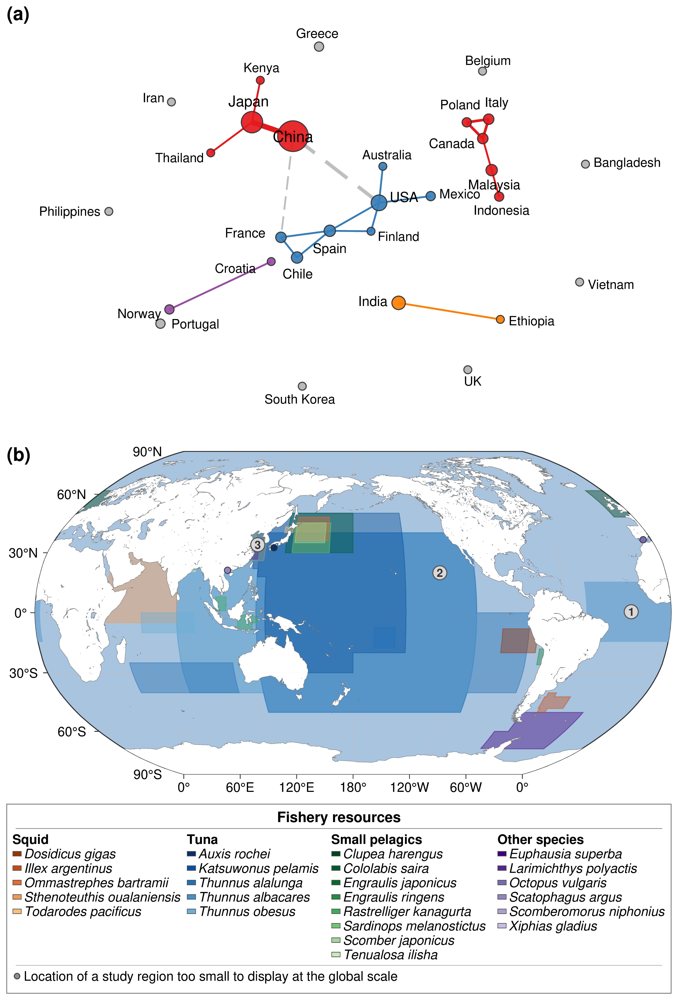

In [3]:
# Figure 3: country collaboration network and coordinate-defined applications
figure_3, fig3_pdf, fig3_png, country_network_statistics = create_figure_3(
    INPUT_CSV,
    DATA_DIR / "Coordinate.csv",
    FIGURE_DIR,
)
display(country_network_statistics.to_frame('Value'))
display(IPythonImage(filename=str(fig3_png), width=900))


Fish groups: ['Squid', 'Tuna', 'Small Pelagics', 'Other Species']
Records: 123 total; 123 analysed
Multi-group papers: 8
Algorithm labels: 83 total; Top 20 displayed by paper frequency

=== Fish Group x Algorithm Profile: paper-level stratified permutation ===
Primary (all 83 labels): statistic=270.68, p=0.00521
Sensitivity (the 20 displayed algorithms): statistic=80.85, p=0.00086
Unstratified global sensitivity: all=0.01480; displayed=0.00159
Exploratory per-algorithm tests (paper-level permutation; BH corrected):
Algorithm  Permutation statistic  Permutation p  BH-adjusted p
      GAM               13.94816        0.00264        0.05280
    ARIMA               10.69879        0.00664        0.06020
     LSTM               10.23010        0.00956        0.06020
 CatBoost               11.11543        0.01204        0.06020
      CNN                9.74491        0.01532        0.06128
       RF                9.14222        0.02698        0.08993
       DT                4.51507      

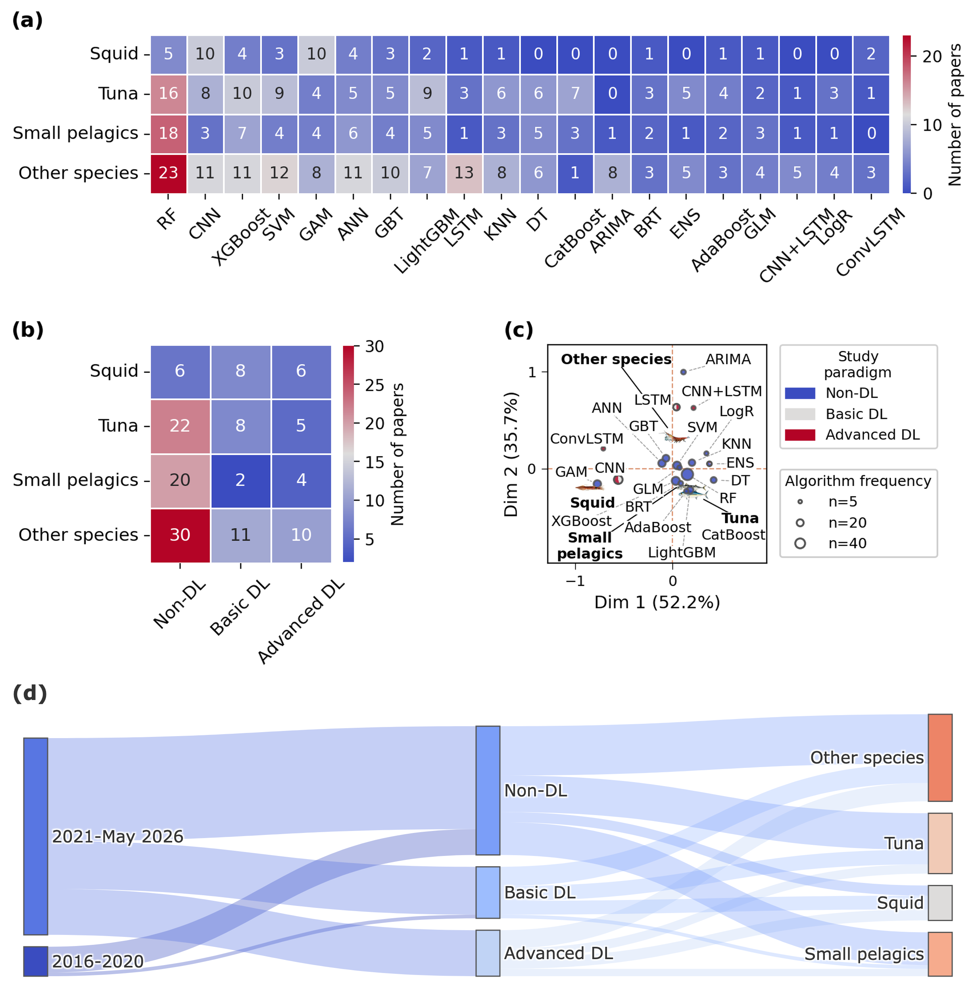

Figure 4 saved: figure/Fig_04.pdf, figure/Fig_04.png


In [4]:
# Figure 4: algorithms and paradigms across fishery-resource groups
df_fig4 = df.copy()


# Deduplicate labels within each paper: the paper, rather than each algorithm mention,
# is the unit of analysis.
df_fig4['kw_list'] = df_fig4['Algorithm'].apply(
    unique_multivalue
)
df_fig4['Fish_Group_list'] = df_fig4['Fish_Group'].apply(
    unique_multivalue
)

# Exclude records lacking any of the three fields required for the association tests.
analysis_mask = (
    df_fig4['kw_list'].map(bool)
    & df_fig4['Fish_Group_list'].map(bool)
    & df_fig4['LM_Category'].notna()
)
df_analysis = df_fig4.loc[analysis_mask].reset_index(drop=True).copy()
df_fig4_groups = df_analysis.explode('Fish_Group_list', ignore_index=True).copy()

all_keywords_fig4 = [kw for kw_list in df_analysis['kw_list'] for kw in kw_list]
kw_freq_fig4 = (
    pd.Series(all_keywords_fig4).value_counts()
    .rename_axis('Algorithm').reset_index(name='Frequency')
    .sort_values(['Frequency', 'Algorithm'], ascending=[False, True], kind='stable')
    .set_index('Algorithm')['Frequency']
)
all_methods_fig4 = kw_freq_fig4.index.tolist()
TOP_METHODS_FIG4 = 20
top_methods_fig4 = kw_freq_fig4.head(TOP_METHODS_FIG4).index.tolist()

MIN_PAPERS_PER_GROUP = 3
N_PERMUTATIONS = 99_999
PERMUTATION_SEED = 42

n_segments = 9
indices = [0, (n_segments - 1) // 2, n_segments - 1]
coolwarm_full = plt.colormaps['coolwarm']
coolwarm_colors = [coolwarm_full(i / (n_segments - 1)) for i in indices]
coolwarm_cmap = LinearSegmentedColormap.from_list("coolwarm_3stop", coolwarm_colors, N=256)

fish_group_counts = df_fig4_groups['Fish_Group_list'].value_counts()
fish_groups_original = fish_group_counts[fish_group_counts >= MIN_PAPERS_PER_GROUP].index.tolist()
fish_groups = ['Squid', 'Tuna', 'Small Pelagics', 'Other Species']
fish_groups = [g for g in fish_groups if g in fish_groups_original]
print(f"Fish groups: {fish_groups}")
print(f"Records: {len(df_fig4)} total; {len(df_analysis)} analysed")
print(f"Multi-group papers: {(df_analysis['Fish_Group_list'].map(len) > 1).sum()}")
print(f"Algorithm labels: {len(all_methods_fig4)} total; "
      f"Top {len(top_methods_fig4)} displayed by paper frequency")

cat_order_full = ['non-DL', 'basic DL', 'advanced DL']
cat_order_short = ['Non-DL', 'Basic DL', 'Advanced DL']

# Paper-level multi-hot matrices. Fish-group memberships remain fixed while entire
# algorithm profiles or paradigm labels are permuted within publication year.
fish_membership = np.asarray([
    [fg in groups for fg in fish_groups]
    for groups in df_analysis['Fish_Group_list']
], dtype=int)
algorithm_all = np.asarray([
    [method in methods for method in all_methods_fig4]
    for methods in df_analysis['kw_list']
], dtype=int)
algorithm_common = np.asarray([
    [method in methods for method in top_methods_fig4]
    for methods in df_analysis['kw_list']
], dtype=int)
paradigm_matrix = np.asarray([
    [category == value for category in cat_order_full]
    for value in df_analysis['LM_Category']
], dtype=int)

count_matrix = pd.DataFrame(
    fish_membership.T @ algorithm_common,
    index=fish_groups, columns=top_methods_fig4, dtype=int,
)
ct_cat = pd.DataFrame(
    fish_membership.T @ paradigm_matrix,
    index=fish_groups, columns=cat_order_full, dtype=int,
)


observed_all = pearson_statistic(fish_membership.T @ algorithm_all)
observed_common = pearson_statistic(count_matrix.values)
observed_category = pearson_statistic(ct_cat.values)
category_pairs = [(i, j) for i in range(len(fish_groups))
                  for j in range(i + 1, len(fish_groups))]
observed_category_pairs = np.asarray([
    pearson_statistic(ct_cat.values[[i, j], :]) for i, j in category_pairs
])
observed_methods = binary_presence_statistics(
    count_matrix.values, fish_membership.sum(axis=0)
)
observed_methods_scipy = np.asarray([
    chi2_contingency(
        np.column_stack([
            count_matrix.values[:, i],
            fish_membership.sum(axis=0) - count_matrix.values[:, i],
        ]),
        correction=False,
    ).statistic
    for i in range(count_matrix.shape[1])
])
np.testing.assert_allclose(observed_methods, observed_methods_scipy, atol=1e-12, rtol=0)

year_values = df_analysis['Year'].to_numpy()
year_strata = [np.flatnonzero(year_values == year) for year in np.unique(year_values)]
rng = np.random.default_rng(PERMUTATION_SEED)
exceed_all = exceed_common = exceed_category = 0
exceed_category_pairs = np.zeros(len(category_pairs), dtype=int)
exceed_methods = np.zeros(len(top_methods_fig4), dtype=int)
base_indices = np.arange(len(df_analysis))

for _ in range(N_PERMUTATIONS):
    permuted_indices = base_indices.copy()
    for stratum in year_strata:
        permuted_indices[stratum] = rng.permutation(stratum)

    perm_all_counts = fish_membership.T @ algorithm_all[permuted_indices]
    perm_common_counts = fish_membership.T @ algorithm_common[permuted_indices]
    perm_category_counts = fish_membership.T @ paradigm_matrix[permuted_indices]

    exceed_all += pearson_statistic(perm_all_counts) >= observed_all - 1e-12
    exceed_common += pearson_statistic(perm_common_counts) >= observed_common - 1e-12
    exceed_category += pearson_statistic(perm_category_counts) >= observed_category - 1e-12
    perm_category_pair_stats = np.asarray([
        pearson_statistic(perm_category_counts[[i, j], :])
        for i, j in category_pairs
    ])
    exceed_category_pairs += perm_category_pair_stats >= observed_category_pairs - 1e-12
    perm_method_stats = binary_presence_statistics(
        perm_common_counts, fish_membership.sum(axis=0)
    )
    exceed_methods += perm_method_stats >= observed_methods - 1e-12

p_all = (exceed_all + 1) / (N_PERMUTATIONS + 1)
p_common = (exceed_common + 1) / (N_PERMUTATIONS + 1)
p_category = (exceed_category + 1) / (N_PERMUTATIONS + 1)
p_category_pairs = (exceed_category_pairs + 1) / (N_PERMUTATIONS + 1)
q_category_pairs = benjamini_hochberg(p_category_pairs)
p_methods = (exceed_methods + 1) / (N_PERMUTATIONS + 1)
q_methods = benjamini_hochberg(p_methods)
validate_bh(p_category_pairs, q_category_pairs)
validate_bh(p_methods, q_methods)

# Unstratified global sensitivity tests use the same statistics, Monte Carlo
# correction, number of permutations and seed as the primary analysis.
rng_unstratified = np.random.default_rng(PERMUTATION_SEED)
exceed_all_unstratified = 0
exceed_common_unstratified = 0
exceed_category_unstratified = 0
for _ in range(N_PERMUTATIONS):
    permuted_indices = rng_unstratified.permutation(base_indices)
    perm_all_counts = fish_membership.T @ algorithm_all[permuted_indices]
    perm_common_counts = fish_membership.T @ algorithm_common[permuted_indices]
    perm_category_counts = fish_membership.T @ paradigm_matrix[permuted_indices]
    exceed_all_unstratified += (
        pearson_statistic(perm_all_counts) >= observed_all - 1e-12
    )
    exceed_common_unstratified += (
        pearson_statistic(perm_common_counts) >= observed_common - 1e-12
    )
    exceed_category_unstratified += (
        pearson_statistic(perm_category_counts) >= observed_category - 1e-12
    )
p_all_unstratified = (exceed_all_unstratified + 1) / (N_PERMUTATIONS + 1)
p_common_unstratified = (exceed_common_unstratified + 1) / (N_PERMUTATIONS + 1)
p_category_unstratified = (exceed_category_unstratified + 1) / (N_PERMUTATIONS + 1)

method_tests = pd.DataFrame({
    'Algorithm': top_methods_fig4,
    'Permutation statistic': observed_methods,
    'Permutation p': p_methods,
    'BH-adjusted p': q_methods,
}).sort_values(['BH-adjusted p', 'Permutation p', 'Algorithm'])

print(f"\n=== Fish Group x Algorithm Profile: paper-level stratified permutation ===")
print(f"Primary (all {len(all_methods_fig4)} labels): "
      f"statistic={observed_all:.2f}, p={p_all:.5f}")
print(f"Sensitivity (the {len(top_methods_fig4)} displayed algorithms): "
      f"statistic={observed_common:.2f}, p={p_common:.5f}")
print(f"Unstratified global sensitivity: all={p_all_unstratified:.5f}; "
      f"displayed={p_common_unstratified:.5f}")
print("Exploratory per-algorithm tests (paper-level permutation; BH corrected):")
print(method_tests.to_string(index=False, float_format=lambda x: f'{x:.5f}'))

print(f"\n=== Fish Group x Methodological Paradigm: paper-level stratified permutation ===")
print(f"statistic={observed_category:.2f}, p={p_category:.5f}")
print(f"Unstratified global sensitivity: p={p_category_unstratified:.5f}")
if p_category < 0.05:
    category_pair_tests = pd.DataFrame({
        'Comparison': [f'{fish_groups[i]} vs {fish_groups[j]}' for i, j in category_pairs],
        'Permutation statistic': observed_category_pairs,
        'Permutation p': p_category_pairs,
        'BH-adjusted p': q_category_pairs,
    }).sort_values(['BH-adjusted p', 'Permutation p', 'Comparison'])
    print("Post-hoc fish-group comparisons (BH corrected):")
    print(category_pair_tests.to_string(index=False, float_format=lambda x: f'{x:.5f}'))
else:
    print("No post-hoc paradigm comparisons were performed because the global test was not significant.")

# Standard correspondence analysis with row- and column-mass scaling.
ca_observed = count_matrix.to_numpy(dtype=float)
ca_proportions = ca_observed / ca_observed.sum()
ca_row_masses = ca_proportions.sum(axis=1)
ca_column_masses = ca_proportions.sum(axis=0)
ca_independence = np.outer(ca_row_masses, ca_column_masses)
ca_standardized = (ca_proportions - ca_independence) / np.sqrt(ca_independence)
U, S, Vt = np.linalg.svd(ca_standardized, full_matrices=False)
fish_coords = (U[:, :2] * S[:2]) / np.sqrt(ca_row_masses)[:, None]
method_coords = (Vt[:2, :].T * S[:2]) / np.sqrt(ca_column_masses)[:, None]
total_var = np.sum(S ** 2)
explained_var = (S[:2] ** 2 / total_var) * 100

fig = plt.figure(figsize=(10, 6))
gs = fig.add_gridspec(2, 2, height_ratios=[0.8, 1.1], width_ratios=[0.3, 1], hspace=0.8, wspace=-0.2)
ax0 = fig.add_subplot(gs[0, :])
ax1 = fig.add_subplot(gs[1, 0])
ax2 = fig.add_subplot(gs[1, 1])

# (a)
fish_group_display = {
    'Small Pelagics': 'Small pelagics',
    'Other Species': 'Other species',
}
fish_group_labels = [fish_group_display.get(group, group) for group in fish_groups]
count_matrix_display = count_matrix.copy()
count_matrix_display.index = fish_group_labels
sns.heatmap(count_matrix_display, annot=True, fmt='d', cmap=coolwarm_cmap,
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Number of papers', 'shrink': 0.99, 'pad': 0.015},
    ax=ax0, annot_kws={'fontsize': 10})
ax0.tick_params(axis='x', rotation=45, labelsize=11)
ax0.tick_params(axis='y', labelsize=11)

# (b)
matrix_cat_display = ct_cat.copy()
matrix_cat_display.columns = cat_order_short
matrix_cat_display.index = fish_group_labels

sns.heatmap(
    matrix_cat_display, annot=True, fmt='d', cmap=coolwarm_cmap,
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Number of papers', 'shrink': 0.99},
    ax=ax1, annot_kws={'fontsize': 11},
)
ax1.tick_params(axis='x', rotation=45, labelsize=11)
ax1.tick_params(axis='y', labelsize=11)
ax1.set_ylabel('')

# (c)
method_cat_dist = method_category_distribution(
    top_methods_fig4, df_analysis, algorithms_column='kw_list'
)
CAT_COLORS_CA = sci_palette

ca_scale = 0.008
fish_image_half_width = 0.16

squid_img_ca = mpimg.imread('./figure/fig_element/Squid_O.bartramii.png')
sq_h, sq_w = squid_img_ca.shape[:2]
tuna_img_ca = mpimg.imread('./figure/fig_element/Tuna_T.alalunga.png')
tu_h, tu_w = tuna_img_ca.shape[:2]
sp_img_ca = mpimg.imread('./figure/fig_element/Small-pelagics_S.scombrus.png')
sp_h, sp_w = sp_img_ca.shape[:2]
other_img_ca = mpimg.imread('./figure/fig_element/Other-species_Krill.png')
ot_h, ot_w = other_img_ca.shape[:2]
fish_label_positions = {
    'Squid': (-0.82, -0.36),
    'Tuna': (0.70, -0.52),
    'Small Pelagics': (-0.85, -0.80),
    'Other Species': (-0.58, 1.12),
}

for i, fg in enumerate(fish_groups):
    if fg == 'Squid':
        ax2.imshow(squid_img_ca, aspect='auto', extent=(fish_coords[i,0]-fish_image_half_width, fish_coords[i,0]+fish_image_half_width, fish_coords[i,1]-fish_image_half_width*sq_h/sq_w, fish_coords[i,1]+fish_image_half_width*sq_h/sq_w), zorder=5)
    elif fg == 'Tuna':
        ax2.imshow(tuna_img_ca, aspect='auto', extent=(fish_coords[i,0]-fish_image_half_width, fish_coords[i,0]+fish_image_half_width, fish_coords[i,1]-fish_image_half_width*tu_h/tu_w, fish_coords[i,1]+fish_image_half_width*tu_h/tu_w), zorder=0)
    elif fg == 'Small Pelagics':
        ax2.imshow(sp_img_ca, aspect='auto', extent=(fish_coords[i,0]-fish_image_half_width, fish_coords[i,0]+fish_image_half_width, fish_coords[i,1]-fish_image_half_width*sp_h/sp_w, fish_coords[i,1]+fish_image_half_width*sp_h/sp_w), zorder=0)
    elif fg == 'Other Species':
        ax2.imshow(other_img_ca, aspect='auto', extent=(fish_coords[i,0]-fish_image_half_width, fish_coords[i,0]+fish_image_half_width, fish_coords[i,1]-fish_image_half_width*ot_h/ot_w, fish_coords[i,1]+fish_image_half_width*ot_h/ot_w), zorder=0)
    label_x, label_y = fish_label_positions[fg]
    fish_line_target = (fish_coords[i, 0], fish_coords[i, 1])
    fish_line_shrink = 7
    if fg == 'Small Pelagics':
        # Route the small-pelagic connector to the fish head.
        fish_line_target = (fish_coords[i, 0] - 0.90 * fish_image_half_width,
                            fish_coords[i, 1])
        fish_line_shrink = 0.5
    # Draw connectors beneath text labels.
    ax2.annotate(
        '', xy=fish_line_target,
        xytext=(label_x, label_y), textcoords='data',
        arrowprops={'arrowstyle': '-', 'color': 'black', 'linewidth': 0.7,
                    'linestyle': '-', 'shrinkA': 2, 'shrinkB': fish_line_shrink},
        zorder=2,
    )
    ax2.annotate(
        'Small\npelagics' if fg == 'Small Pelagics' else fish_group_display.get(fg, fg),
        xy=(fish_coords[i, 0], fish_coords[i, 1]),
        xytext=(label_x, label_y), textcoords='data',
        fontsize=9, fontweight='bold', ha='center', va='center',
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 0.1},
        zorder=6,
    )

for i, m in enumerate(top_methods_fig4):
    x, y = method_coords[i, 0], method_coords[i, 1]
    dist = method_cat_dist[m]
    total = sum(dist.values())
    radius = np.sqrt(kw_freq_fig4.get(m, 1)) * ca_scale
    if m in METHOD_NODE_COLOR_OVERRIDES:
        circle = Circle((x, y), radius, facecolor=METHOD_NODE_COLOR_OVERRIDES[m],
                        edgecolor='#555555', linewidth=1.2, alpha=0.85, zorder=3)
        ax2.add_patch(circle)
    elif len(dist) <= 1:
        color = CAT_COLORS_CA.get(list(dist.keys())[0] if dist else "non-DL", "#999999")
        circle = Circle((x, y), radius, facecolor=color, edgecolor='#555555', linewidth=1.2, alpha=0.85, zorder=3)
        ax2.add_patch(circle)
    else:
        start = 90
        for cat, count in sorted(dist.items(), key=lambda x: -x[1]):
            sweep = count / total * 360
            color = CAT_COLORS_CA.get(cat, "#999999")
            wedge = Wedge((x, y), radius, start, start + sweep, facecolor=color, edgecolor='none', alpha=0.85, zorder=3)
            ax2.add_patch(wedge)
            start += sweep
        border = Circle((x, y), radius, facecolor='none', edgecolor='#555555', linewidth=1.2, zorder=4)
        ax2.add_patch(border)

# Place algorithm labels and draw connectors to their nodes.
method_label_positions_fig4 = {
    'RF': (0.57, -0.31), 'CNN': (-0.64, 0.00),
    'XGBoost': (-0.94, -0.55), 'SVM': (0.31, 0.42),
    'GAM': (-1.04, -0.04), 'ANN': (-0.67, 0.62),
    'GBT': (-0.30, 0.43), 'LightGBM': (0.10, -0.87),
    'LSTM': (-0.20, 0.70), 'KNN': (0.66, 0.25),
    'DT': (0.70, -0.13), 'CatBoost': (0.63, -0.69),
    'ARIMA': (0.58, 1.12), 'BRT': (-0.35, -0.40),
    'ENS': (0.70, 0.05), 'AdaBoost': (-0.15, -0.61),
    'GLM': (-0.25, -0.22), 'CNN+LSTM': (0.51, 0.79),
    'LogR': (0.66, 0.58), 'ConvLSTM': (-0.88, 0.30),
}
method_annotations_fig4 = []
for i, method in enumerate(top_methods_fig4):
    x, y = method_coords[i, 0], method_coords[i, 1]
    radius = np.sqrt(kw_freq_fig4.get(method, 1)) * ca_scale
    label_x, label_y = method_label_positions_fig4[method]
    ax2.annotate(
        '', xy=(x, y), xytext=(label_x, label_y), textcoords='data',
        arrowprops={'arrowstyle': '-', 'color': '#999999',
                    'linewidth': 0.55, 'linestyle': (0, (3, 2)),
                    'shrinkA': 2, 'shrinkB': 4}, zorder=2,
    )
    annotation = ax2.annotate(
        method, xy=(x, y), xytext=(label_x, label_y), textcoords='data',
        fontsize=9, color='black', ha='center', va='center',
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 0.1},
        zorder=7,
    )
    method_annotations_fig4.append(annotation)

# Match the XAI-bar orange in Figure 2c (c_xai), including its opacity.
zero_axis_color_fig4 = (0.85, 0.55, 0.40, 0.90)
ax2.axhline(0, color=zero_axis_color_fig4, linewidth=0.8, linestyle='--')
ax2.axvline(0, color=zero_axis_color_fig4, linewidth=0.8, linestyle='--')
ax2.set_xlabel(f'Dim 1 ({explained_var[0]:.1f}%)', fontsize=11)
ax2.set_ylabel(f'Dim 2 ({explained_var[1]:.1f}%)', fontsize=11)
ax2.tick_params(axis='both', length=4, width=0.5, labelsize=9)

cat_handles = [
    mpatches.Patch(color=CAT_COLORS_CA["non-DL"], label='Non-DL'),
    mpatches.Patch(color=CAT_COLORS_CA["basic DL"], label='Basic DL'),
    mpatches.Patch(color=CAT_COLORS_CA["advanced DL"], label='Advanced DL'),
]
# Keep both legends immediately outside the data rectangle; bbox_inches='tight'
# expands the exported canvas to contain them without overlaying panel (c).
legend2 = ax2.legend(
    handles=cat_handles, fontsize=9, loc='upper left',
    bbox_to_anchor=(1.06, 1, 0.72, 0), mode='expand', borderaxespad=0,
    framealpha=0.9, title='Study\nparadigm', title_fontsize=9,
)
legend2.get_title().set_ha('center')
legend2.get_title().set_multialignment('center')
ax2.add_artist(legend2)

# Recompute data limits before setting equal axis ranges.
ax2.relim()
ax2.autoscale_view()
# Use equal numerical ranges and an equal physical box so the CA panel is square.
ca_xlim = ax2.get_xlim()
ca_ylim = ax2.get_ylim()
ca_x_center = sum(ca_xlim) / 2
ca_y_center = sum(ca_ylim) / 2
# Add padding for labels near the CA-panel border (for example ARIMA, Tuna
# and CatBoost) while retaining equal x/y ranges and a square panel.
ca_half_range = 1.18 * max(
    ca_xlim[1] - ca_xlim[0], ca_ylim[1] - ca_ylim[0]
) / 2
ax2.set_xlim(ca_x_center - ca_half_range, ca_x_center + ca_half_range)
ax2.set_ylim(ca_y_center - ca_half_range, ca_y_center + ca_half_range)
ax2.set_box_aspect(1)
ax2.set_aspect('equal', adjustable='box')
ax2.locator_params(axis='both', nbins=4)
# Convert the data-coordinate node radii to physical points so the legend
# circles are exactly the same displayed size as nodes of equal frequency.
fig.canvas.draw()
freq_samples = [5, 20, 40]
origin_px = ax2.transData.transform((0, 0))
freq_handles = []
for freq in freq_samples:
    radius_data = np.sqrt(freq) * ca_scale
    radius_px = abs(ax2.transData.transform((radius_data, 0))[0] - origin_px[0])
    diameter_points = 2 * radius_px * 72 / fig.dpi
    freq_handles.append(Line2D(
        [0], [0], marker='o', linestyle='None', markersize=diameter_points,
        markerfacecolor='none', markeredgecolor='#555555',
        markeredgewidth=1.2, label=f'n={freq}'
    ))
legend3 = ax2.legend(
    handles=freq_handles, loc='upper left',
    bbox_to_anchor=(1.06, 0.43, 0.72, 0), mode='expand', borderaxespad=0,
    fontsize=9, framealpha=0.9, title='Algorithm frequency',
    title_fontsize=9, handletextpad=1,
)
legend3.get_title().set_ha('center')
legend3.get_title().set_multialignment('center')
ax2.add_artist(legend3)


# Position panel labels from the full tight bounds (including y tick labels
# and y-axis labels), rather than from the inner plotting rectangles.
# Panels (b) and (c) share the fixed top of the second GridSpec row so their
# labels remain exactly level despite different axes contents and legends.
fig.canvas.draw()
renderer_fig4 = fig.canvas.get_renderer()
panel_bounds_fig4 = {
    panel_label: panel_ax.get_tightbbox(renderer_fig4).transformed(
        fig.transFigure.inverted()
    )
    for panel_label, panel_ax in [('a', ax0), ('b', ax1), ('c', ax2)]
}
fig.text(panel_bounds_fig4['a'].x0, panel_bounds_fig4['a'].y1 + 0.006,
         '(a)', fontsize=13, fontweight='bold', va='bottom', ha='left')
second_row_label_y_fig4 = gs[1, 0].get_position(fig).y1 + 0.006
for panel_label in ['b', 'c']:
    fig.text(panel_bounds_fig4[panel_label].x0, second_row_label_y_fig4,
             f'({panel_label})', fontsize=13, fontweight='bold',
             va='bottom', ha='left')

# Save (a-c) as vector PDF AND PNG preview
ac_pdf = str(TEMP_DIR / 'Fig_04_ac.pdf')
ac_png_preview = str(TEMP_DIR / 'Fig_04_ac.png')
fig.savefig(ac_pdf, bbox_inches='tight', facecolor='white', edgecolor='none')
fig.savefig(ac_png_preview, dpi=200, bbox_inches='tight', facecolor='white', edgecolor='none')
plt.close(fig)

# ======== (d) Sankey Diagram: Year Group → ML Paradigm → Fish Group ========
df_s2 = df_fig4.copy()
df_s2['Fish_Group_list'] = df_s2['Fish_Group'].apply(split_multivalue)
df_s2 = df_s2[
    df_s2['Year'].notna()
    & df_s2['LM_Category'].notna()
    & df_s2['Fish_Group_list'].map(bool)
].copy()
# Split one paper across its fish groups while preserving total paper flow.
df_s2['Fish_Group_weight'] = 1.0 / df_s2['Fish_Group_list'].map(len)
df_s2 = df_s2.explode('Fish_Group_list', ignore_index=True)


df_s2['Year_Group'] = df_s2['Year'].apply(assign_year_group)
l1 = (df_s2.groupby(['Year_Group', 'LM_Category'])['Fish_Group_weight']
      .sum().reset_index(name='c'))
l2 = (df_s2.groupby(['LM_Category', 'Fish_Group_list'])['Fish_Group_weight']
      .sum().reset_index(name='c'))

sl, tl, v = [], [], []
for _, r in l1.iterrows():
    sl.append(r['Year_Group']); tl.append(r['LM_Category']); v.append(r['c'])
for _, r in l2.iterrows():
    sl.append(r['LM_Category']); tl.append(r['Fish_Group_list']); v.append(r['c'])

no = ['2016-2020','2021-May 2026',
      'non-DL','basic DL','advanced DL',
      'Squid','Tuna','Small Pelagics','Other Species']
node_labels = ['2016-2020','2021-May 2026',
               'Non-DL','Basic DL','Advanced DL',
               'Squid','Tuna','Small pelagics','Other species']
nti = {n: i for i, n in enumerate(no)}
si = [nti[s] for s in sl]; ti = [nti[t] for t in tl]

p11 = [
    f'rgb({int(r*255)},{int(g*255)},{int(b*255)})'
    for r, g, b, _ in (coolwarm_full(i/10) for i in range(11))
]
lc = []
for s in sl:
    b = p11[nti[s]]
    vs = [float(x) for x in re.findall(r'[\d.]+', b)]
    lc.append(f'rgba({int(vs[0])},{int(vs[1])},{int(vs[2])},0.35)')

fig_sankey = go.Figure(data=[go.Sankey(
    arrangement='snap',
    node=dict(pad=10, thickness=20, line=dict(color='#555555', width=1),
              label=node_labels, color=p11,
              hovertemplate='%{label}<extra></extra>'),
    link=dict(source=si, target=ti, value=v, color=lc,
              hovertemplate='%{source.label} → %{target.label}: %{value}<extra></extra>')
)])
fig_sankey.update_layout(font=dict(size=14, color='#333333'), width=820, height=270,
                        margin=dict(l=20, r=20, t=30, b=20),
                        annotations=[dict(
                            x=-0.015, y=1.14,
                            xref='paper', yref='paper',
                            text='<b>(d)</b>',
                            showarrow=False,
                            xanchor='left',
                            font=dict(size=17, color='#333333')
                        )])

# --- Combine Fig_04 (a–c) + Sankey (d) into single-page vector PDF ---
sankey_pdf = str(TEMP_DIR / 'Fig_04_d.pdf')
pio.write_image(fig_sankey, sankey_pdf, format='pdf', width=820, height=270)


pages_ac = PdfReaderRW(ac_pdf).pages
pages_d = PdfReaderRW(sankey_pdf).pages

h_ac = float(pages_ac[0].MediaBox[3]) - float(pages_ac[0].MediaBox[1])
h_d = float(pages_d[0].MediaBox[3]) - float(pages_d[0].MediaBox[1])

merged_page = PageMerge()
merged_page.add(pages_ac[0])
merged_page.add(pages_d[0])
merged_page[0].y = h_d
merged_page[1].y = 0

writer_rw = PdfWriterRW()
writer_rw.addpage(merged_page.render())
writer_rw.write(str(FIGURE_DIR / 'Fig_04.pdf'))

# Cleanup temp PDF files
for tmp in [ac_pdf, sankey_pdf]:
    try:
        os.remove(tmp)
    except OSError:
        pass

# --- Display merged figure in notebook as PNG preview ---
sankey_png_preview = str(TEMP_DIR / 'Fig_04_d.png')
pio.write_image(fig_sankey, sankey_png_preview, format='png', width=820, height=270, scale=3)

PILImage = Image

img_ac = PILImage.open(ac_png_preview)
img_sk = PILImage.open(sankey_png_preview)

w_ac, h_ac_img = img_ac.size
w_sk, h_sk_img = img_sk.size
target_w = max(w_ac, w_sk)
if w_ac != target_w:
    img_ac = img_ac.resize((target_w, int(h_ac_img * target_w / w_ac)), PILImage.LANCZOS)
    h_ac_img = int(h_ac_img * target_w / w_ac)
if w_sk != target_w:
    img_sk = img_sk.resize((target_w, int(h_sk_img * target_w / w_sk)), PILImage.LANCZOS)
    h_sk_img = int(h_sk_img * target_w / w_sk)

combined_fig = PILImage.new('RGB', (target_w, h_ac_img + h_sk_img), 'white')
combined_fig.paste(img_ac, (0, 0))
combined_fig.paste(img_sk, (0, h_ac_img))

combined_preview = str(FIGURE_DIR / 'Fig_04.png')
combined_fig.save(combined_preview, 'PNG')
display(IPythonImage(filename=combined_preview, width=target_w//2))
print(f'Figure 4 saved: {FIGURE_DIR / "Fig_04.pdf"}, {combined_preview}')

# Remove temporary raster components after the final figure has been assembled.
for tmp in [ac_png_preview, sankey_png_preview]:
    try:
        os.remove(tmp)
    except OSError:
        pass

Abbreviation definitions still needed in data/Abbr.csv: SSH-grad, SSS-grad, SST-front, SST-grad, ST-grad

=== Predictor x Target: paper-level stratified permutation ===
Records: 123 total; 123 analysed
Labels: 181 predictors; 12 targets
Displayed predictors (Top 20): 20
Primary (all predictors): statistic=3362.15, p=0.00004
Sensitivity (displayed predictors): statistic=258.44, p=0.00009
Unstratified global sensitivity: all=0.00067; displayed=0.00013
FDR-significant Predictor-Target cells:
Predictor             Target  Papers  Permutation z  Permutation p  BH-adjusted p
    Speed Fishing operations       7        7.89759        0.00001        0.00240


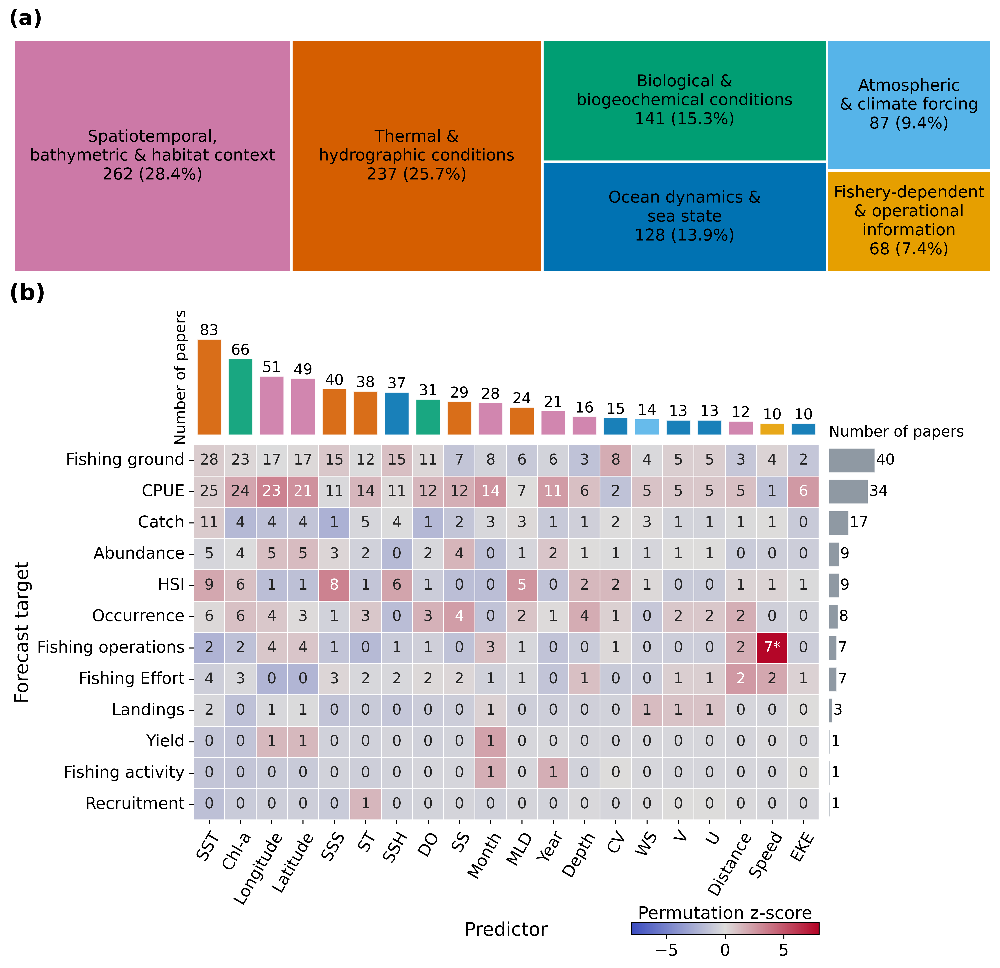

In [5]:
# Figure 5: predictor domains and predictor-target associations
df_fig5 = df.copy()
ABBR_CSV = DATA_DIR / 'Abbr.csv'
PREDICTOR_CATEGORY_CSV = DATA_DIR / 'Predictor_category.csv'
TOP_PREDICTORS_FIG5 = 20
N_PERMUTATIONS_FIG5 = 99_999
PERMUTATION_SEED_FIG5 = 42
abbr_definitions_fig5 = load_abbreviation_definitions(ABBR_CSV)


df_fig5['Predictor_list'] = df_fig5['Predictor'].apply(split_multivalue)
df_fig5['Target_list'] = df_fig5['Target'].apply(split_multivalue)

# Validate the manually checked coding rather than silently deduplicating it.
duplicate_predictor_rows = df_fig5.loc[
    df_fig5['Predictor_list'].apply(lambda values: len(values) != len(set(values))), 'No.'
].tolist()
duplicate_target_rows = df_fig5.loc[
    df_fig5['Target_list'].apply(lambda values: len(values) != len(set(values))), 'No.'
].tolist()
if duplicate_predictor_rows or duplicate_target_rows:
    raise ValueError(
        f'Duplicate labels detected within papers: predictors={duplicate_predictor_rows}, '
        f'targets={duplicate_target_rows}'
    )

analysis_mask_fig5 = (
    df_fig5['Predictor_list'].map(bool) & df_fig5['Target_list'].map(bool)
)
df_fig5_analysis = df_fig5.loc[analysis_mask_fig5].reset_index(drop=True).copy()

predictor_frequency = pd.Series(
    [label for labels in df_fig5_analysis['Predictor_list'] for label in labels]
).value_counts()
target_frequency = pd.Series(
    [label for labels in df_fig5_analysis['Target_list'] for label in labels]
).value_counts()
all_predictors = predictor_frequency.index.tolist()
display_predictors = predictor_frequency.head(TOP_PREDICTORS_FIG5).index.tolist()
all_targets = target_frequency.index.tolist()
abbreviation_like_predictors = [
    label for label in all_predictors
    if re.fullmatch(r'[A-Z][A-Z0-9+.-]*', label)
    or re.fullmatch(r'[A-Z]{2,}[A-Za-z]*-(?:grad|front)', label)
]
undefined_predictor_abbreviations = sorted(
    set(abbreviation_like_predictors) - set(abbr_definitions_fig5)
)
if undefined_predictor_abbreviations:
    print(
        f'Abbreviation definitions still needed in {ABBR_CSV}: '
        + ', '.join(undefined_predictor_abbreviations)
    )

predictor_category_table_fig5 = pd.read_csv(PREDICTOR_CATEGORY_CSV)
required_category_columns_fig5 = {'Predictor', 'Category', 'Papers'}
if set(predictor_category_table_fig5.columns) != required_category_columns_fig5:
    raise ValueError(
        f'{PREDICTOR_CATEGORY_CSV} must contain exactly '
        f'{sorted(required_category_columns_fig5)}'
    )
if predictor_category_table_fig5['Predictor'].duplicated().any():
    duplicates = predictor_category_table_fig5.loc[
        predictor_category_table_fig5['Predictor'].duplicated(False), 'Predictor'
    ].tolist()
    raise ValueError(f'Duplicate predictor-category mappings: {duplicates}')
predictor_category_fig5 = predictor_category_table_fig5.set_index(
    'Predictor'
)['Category'].to_dict()
mapped_predictors_fig5 = set(predictor_category_fig5)
observed_predictors_fig5 = set(all_predictors)
if mapped_predictors_fig5 != observed_predictors_fig5:
    raise ValueError(
        'Predictor-category coverage mismatch: '
        f'missing={sorted(observed_predictors_fig5 - mapped_predictors_fig5)}, '
        f'extra={sorted(mapped_predictors_fig5 - observed_predictors_fig5)}'
    )
mapped_frequency_fig5 = predictor_category_table_fig5.set_index(
    'Predictor'
)['Papers'].astype(int)
pd.testing.assert_series_equal(
    mapped_frequency_fig5.sort_index(),
    predictor_frequency.astype(int).sort_index(),
    check_names=False,
)

predictor_all_matrix = np.asarray([
    [predictor in labels for predictor in all_predictors]
    for labels in df_fig5_analysis['Predictor_list']
], dtype=int)
predictor_display_matrix = np.asarray([
    [predictor in labels for predictor in display_predictors]
    for labels in df_fig5_analysis['Predictor_list']
], dtype=int)
target_matrix = np.asarray([
    [target in labels for target in all_targets]
    for labels in df_fig5_analysis['Target_list']
], dtype=int)

assert len(df_fig5_analysis) == 123
assert len(all_predictors) == len(predictor_category_table_fig5)
assert len(display_predictors) == TOP_PREDICTORS_FIG5
assert len(all_targets) == 12

observed_all_fig5 = predictor_all_matrix.T @ target_matrix
observed_display_fig5 = predictor_display_matrix.T @ target_matrix


observed_all_stat_fig5 = pearson_statistic(observed_all_fig5)
observed_display_stat_fig5 = pearson_statistic(observed_display_fig5)
observed_all_scipy_fig5 = chi2_contingency(
    observed_all_fig5, correction=False
).statistic
observed_display_scipy_fig5 = chi2_contingency(
    observed_display_fig5, correction=False
).statistic
np.testing.assert_allclose(
    observed_all_stat_fig5, observed_all_scipy_fig5, atol=1e-12, rtol=0
)
np.testing.assert_allclose(
    observed_display_stat_fig5, observed_display_scipy_fig5, atol=1e-12, rtol=0
)
years_fig5 = df_fig5_analysis['Year'].to_numpy()
year_strata_fig5 = [
    np.flatnonzero(years_fig5 == year) for year in np.unique(years_fig5)
]

# Conditional expectation under within-year permutation.
expected_cells_fig5 = np.zeros_like(observed_display_fig5, dtype=float)
for stratum in year_strata_fig5:
    expected_cells_fig5 += np.outer(
        predictor_display_matrix[stratum].sum(axis=0),
        target_matrix[stratum].sum(axis=0),
    ) / len(stratum)

rng_fig5 = np.random.default_rng(PERMUTATION_SEED_FIG5)
base_indices_fig5 = np.arange(len(df_fig5_analysis))
exceed_all_fig5 = 0
exceed_display_fig5 = 0
exceed_cells_fig5 = np.zeros_like(observed_display_fig5, dtype=int)
null_cell_sum_fig5 = np.zeros_like(observed_display_fig5, dtype=float)
null_cell_sumsq_fig5 = np.zeros_like(observed_display_fig5, dtype=float)
observed_cell_deviation_fig5 = np.abs(observed_display_fig5 - expected_cells_fig5)

for _ in range(N_PERMUTATIONS_FIG5):
    permuted_indices = base_indices_fig5.copy()
    for stratum in year_strata_fig5:
        permuted_indices[stratum] = rng_fig5.permutation(stratum)

    permuted_targets = target_matrix[permuted_indices]
    permuted_all = predictor_all_matrix.T @ permuted_targets
    permuted_display = predictor_display_matrix.T @ permuted_targets

    exceed_all_fig5 += (
        pearson_statistic(permuted_all) >= observed_all_stat_fig5 - 1e-12
    )
    exceed_display_fig5 += (
        pearson_statistic(permuted_display) >= observed_display_stat_fig5 - 1e-12
    )
    exceed_cells_fig5 += (
        np.abs(permuted_display - expected_cells_fig5)
        >= observed_cell_deviation_fig5 - 1e-12
    )
    null_cell_sum_fig5 += permuted_display
    null_cell_sumsq_fig5 += permuted_display ** 2

p_all_fig5 = (exceed_all_fig5 + 1) / (N_PERMUTATIONS_FIG5 + 1)
p_display_fig5 = (exceed_display_fig5 + 1) / (N_PERMUTATIONS_FIG5 + 1)
cell_p_fig5 = (exceed_cells_fig5 + 1) / (N_PERMUTATIONS_FIG5 + 1)
cell_q_fig5 = benjamini_hochberg(cell_p_fig5.ravel()).reshape(cell_p_fig5.shape)
validate_bh(cell_p_fig5.ravel(), cell_q_fig5.ravel())

# Unstratified global sensitivity tests; cell-level inference remains based on
# the publication-year-stratified null distribution above.
rng_fig5_unstratified = np.random.default_rng(PERMUTATION_SEED_FIG5)
exceed_all_fig5_unstratified = 0
exceed_display_fig5_unstratified = 0
for _ in range(N_PERMUTATIONS_FIG5):
    permuted_indices = rng_fig5_unstratified.permutation(base_indices_fig5)
    permuted_targets = target_matrix[permuted_indices]
    permuted_all = predictor_all_matrix.T @ permuted_targets
    permuted_display = predictor_display_matrix.T @ permuted_targets
    exceed_all_fig5_unstratified += (
        pearson_statistic(permuted_all) >= observed_all_stat_fig5 - 1e-12
    )
    exceed_display_fig5_unstratified += (
        pearson_statistic(permuted_display)
        >= observed_display_stat_fig5 - 1e-12
    )
p_all_fig5_unstratified = (
    exceed_all_fig5_unstratified + 1
) / (N_PERMUTATIONS_FIG5 + 1)
p_display_fig5_unstratified = (
    exceed_display_fig5_unstratified + 1
) / (N_PERMUTATIONS_FIG5 + 1)
null_cell_mean_fig5 = null_cell_sum_fig5 / N_PERMUTATIONS_FIG5
null_cell_var_fig5 = (
    null_cell_sumsq_fig5
    - N_PERMUTATIONS_FIG5 * null_cell_mean_fig5 ** 2
) / (N_PERMUTATIONS_FIG5 - 1)
null_cell_sd_fig5 = np.sqrt(np.maximum(null_cell_var_fig5, 0))
cell_z_fig5 = np.divide(
    observed_display_fig5 - null_cell_mean_fig5,
    null_cell_sd_fig5,
    out=np.zeros_like(null_cell_mean_fig5),
    where=null_cell_sd_fig5 > 0,
)

association_results_fig5 = pd.DataFrame([
    {
        'Predictor': predictor,
        'Target': target,
        'Papers': int(observed_display_fig5[i, j]),
        'Permutation z': cell_z_fig5[i, j],
        'Permutation p': cell_p_fig5[i, j],
        'BH-adjusted p': cell_q_fig5[i, j],
    }
    for i, predictor in enumerate(display_predictors)
    for j, target in enumerate(all_targets)
]).sort_values(['BH-adjusted p', 'Permutation p', 'Predictor', 'Target'])

print('\n=== Predictor x Target: paper-level stratified permutation ===')
print(f'Records: {len(df_fig5)} total; {len(df_fig5_analysis)} analysed')
print(f'Labels: {len(all_predictors)} predictors; {len(all_targets)} targets')
print(f'Displayed predictors (Top {TOP_PREDICTORS_FIG5}): '
      f'{len(display_predictors)}')
print(f'Primary (all predictors): statistic={observed_all_stat_fig5:.2f}, '
      f'p={p_all_fig5:.5f}')
print(f'Sensitivity (displayed predictors): '
      f'statistic={observed_display_stat_fig5:.2f}, p={p_display_fig5:.5f}')
print(f'Unstratified global sensitivity: all={p_all_fig5_unstratified:.5f}; '
      f'displayed={p_display_fig5_unstratified:.5f}')
significant_cells_fig5 = association_results_fig5[
    association_results_fig5['BH-adjusted p'] < 0.05
]
if significant_cells_fig5.empty:
    print('No individual Predictor-Target cells remained significant after BH correction.')
else:
    print('FDR-significant Predictor-Target cells:')
    print(significant_cells_fig5.to_string(index=False, float_format=lambda x: f'{x:.5f}'))

# Use a zero-centred diverging palette for signed permutation z-scores,
# while matching Figure 6's fill for the marginal frequency bars.
coolwarm_full_fig5 = plt.colormaps['coolwarm']
coolwarm_colors_fig5 = [coolwarm_full_fig5(value) for value in (0.0, 0.5, 1.0)]
coolwarm_cmap_fig5 = LinearSegmentedColormap.from_list(
    'coolwarm_3stop_fig5', coolwarm_colors_fig5, N=256
)
fig5_bar_color = (0.45, 0.50, 0.55, 0.85)  # Target-frequency bars
predictor_category_colors_fig5 = {
    'Thermal & hydrographic conditions': '#D55E00',
    'Biological & biogeochemical conditions': '#009E73',
    'Ocean dynamics & sea state': '#0072B2',
    'Atmospheric & climate forcing': '#56B4E9',
    'Spatiotemporal, bathymetric & habitat context': '#CC79A7',
    'Fishery-dependent & operational information': '#E69F00',
}
unexpected_categories_fig5 = sorted(
    set(predictor_category_fig5.values())
    - set(predictor_category_colors_fig5)
)
if unexpected_categories_fig5:
    raise ValueError(
        f'Categories without Figure 5 colours: {unexpected_categories_fig5}'
    )
predictor_bar_colors_fig5 = [
    predictor_category_colors_fig5[predictor_category_fig5[predictor]]
    for predictor in display_predictors
]

annotation_fig5 = np.asarray([
    [f'{int(observed_display_fig5[i, j])}' + ('*' if cell_q_fig5[i, j] < 0.05 else '')
     for j in range(len(all_targets))]
    for i in range(len(display_predictors))
])
z_limit_fig5 = max(2.0, float(np.ceil(np.nanmax(np.abs(cell_z_fig5)))))

# Draw the final two-panel Figure 5 directly, without intermediate files
FIG5_PDF = FIGURE_DIR / 'Fig_05.pdf'
FIG5_PNG = FIGURE_DIR / 'Fig_05.png'

category_order_fig5 = PREDICTOR_CATEGORY_ORDER
category_labels_fig5 = {
    'Thermal & hydrographic conditions': 'Thermal &\nhydrographic conditions',
    'Biological & biogeochemical conditions': 'Biological &\nbiogeochemical conditions',
    'Ocean dynamics & sea state': 'Ocean dynamics &\nsea state',
    'Atmospheric & climate forcing': 'Atmospheric\n& climate forcing',
    'Spatiotemporal, bathymetric & habitat context': 'Spatiotemporal,\nbathymetric & habitat context',
    'Fishery-dependent & operational information': 'Fishery-dependent\n& operational\ninformation',
}
category_counts_fig5 = (
    predictor_category_table_fig5.groupby('Category')['Papers'].sum().astype(int)
)
if set(category_counts_fig5.index) != set(category_order_fig5):
    raise ValueError('Predictor-category labels do not match the six expected domains')
assert int(category_counts_fig5.sum()) == 923

fig5 = plt.figure(figsize=(12.6, 9.45), facecolor='white')
outer_fig5 = fig5.add_gridspec(
    2, 1, height_ratios=[3.0, 6.45], hspace=0.13,
    left=0.012, right=0.988, top=0.975, bottom=0.055,
)

# Panel (a): deterministic Matplotlib treemap with areas proportional to
# predictor-study occurrences. The two largest domains occupy full-height
# columns; the remaining four form two vertically divided columns.
ax5_tree = fig5.add_subplot(outer_fig5[0])
ax5_tree.set_xlim(0, 1)
ax5_tree.set_ylim(0, 1)
ax5_tree.axis('off')
total_fig5 = float(category_counts_fig5.sum())
spatial_cat = 'Spatiotemporal, bathymetric & habitat context'
thermal_cat = 'Thermal & hydrographic conditions'
bio_cat = 'Biological & biogeochemical conditions'
ocean_cat = 'Ocean dynamics & sea state'
atmos_cat = 'Atmospheric & climate forcing'
fishery_cat = 'Fishery-dependent & operational information'
w_spatial = category_counts_fig5[spatial_cat] / total_fig5
w_thermal = category_counts_fig5[thermal_cat] / total_fig5
w_bio_ocean = (category_counts_fig5[bio_cat] + category_counts_fig5[ocean_cat]) / total_fig5
w_atmos_fishery = (category_counts_fig5[atmos_cat] + category_counts_fig5[fishery_cat]) / total_fig5
tree_rectangles_fig5 = [
    (spatial_cat, 0, 0, w_spatial, 1),
    (thermal_cat, w_spatial, 0, w_thermal, 1),
    (bio_cat, w_spatial + w_thermal, 1 - category_counts_fig5[bio_cat] / (category_counts_fig5[bio_cat] + category_counts_fig5[ocean_cat]), w_bio_ocean, category_counts_fig5[bio_cat] / (category_counts_fig5[bio_cat] + category_counts_fig5[ocean_cat])),
    (ocean_cat, w_spatial + w_thermal, 0, w_bio_ocean, category_counts_fig5[ocean_cat] / (category_counts_fig5[bio_cat] + category_counts_fig5[ocean_cat])),
    (atmos_cat, w_spatial + w_thermal + w_bio_ocean, 1 - category_counts_fig5[atmos_cat] / (category_counts_fig5[atmos_cat] + category_counts_fig5[fishery_cat]), w_atmos_fishery, category_counts_fig5[atmos_cat] / (category_counts_fig5[atmos_cat] + category_counts_fig5[fishery_cat])),
    (fishery_cat, w_spatial + w_thermal + w_bio_ocean, 0, w_atmos_fishery, category_counts_fig5[fishery_cat] / (category_counts_fig5[atmos_cat] + category_counts_fig5[fishery_cat])),
]
# Use a point-based white border so horizontal and vertical spacing has
# the same physical width despite the panel's non-square aspect ratio.
tree_gap_fig5 = 0.0
for category, x0, y0, width, height in tree_rectangles_fig5:
    ax5_tree.add_patch(Rectangle(
        (x0 + tree_gap_fig5, y0 + tree_gap_fig5),
        width - 2 * tree_gap_fig5, height - 2 * tree_gap_fig5,
        facecolor=predictor_category_colors_fig5[category],
        edgecolor='white', linewidth=2.0,
    ))
    value = int(category_counts_fig5[category])
    ax5_tree.text(
        x0 + width / 2, y0 + height / 2,
        f'{category_labels_fig5[category]}\n{value} ({value / total_fig5:.1%})',
        ha='center', va='center', color='black', fontsize=13,
        fontweight='normal', linespacing=1.25,
    )
ax5_tree.text(-0.005, 1.045, '(a)', transform=ax5_tree.transAxes,
              ha='left', va='bottom', fontsize=17, fontweight='bold')

# Panel (b): marginal frequencies and Predictor-Target heatmap.
panel_b_grid_fig5 = outer_fig5[1].subgridspec(
    2, 2, height_ratios=[1.9, 6.2], width_ratios=[14, 2.5],
    hspace=0.04, wspace=0.06,
)
ax4_top = fig5.add_subplot(panel_b_grid_fig5[0, 0])
ax4_heat = fig5.add_subplot(panel_b_grid_fig5[1, 0])
ax4_side = fig5.add_subplot(panel_b_grid_fig5[1, 1], sharey=ax4_heat)
x_predictor_fig5 = np.arange(len(display_predictors)) + 0.5
predictor_values_fig5 = predictor_frequency.loc[display_predictors].values
target_values_fig5 = target_frequency.loc[all_targets].values
target_display_labels_fig5 = [
    {'FG': 'Fishing ground', 'FE': 'Fishing Effort'}.get(target, target)
    for target in all_targets
]
shared_frequency_limit_fig5 = max(predictor_values_fig5.max(), target_values_fig5.max()) * 1.2
ax4_top.bar(x_predictor_fig5, predictor_values_fig5, width=0.78,
            color=predictor_bar_colors_fig5, edgecolor='white', linewidth=0.8, alpha=0.9)
for x, value in zip(x_predictor_fig5, predictor_values_fig5):
    ax4_top.text(x, value + 0.7, str(int(value)), ha='center', va='bottom', fontsize=12)
ax4_top.set_xlim(0, len(display_predictors))
ax4_top.set_ylim(0, shared_frequency_limit_fig5)
ax4_top.set_ylabel('Number of papers', fontsize=12)
ax4_top.set_xticks([])
ax4_top.set_yticks([])
for spine in ax4_top.spines.values():
    spine.set_visible(False)
heatmap_fig5 = sns.heatmap(
    pd.DataFrame(cell_z_fig5.T, index=target_display_labels_fig5, columns=display_predictors),
    annot=annotation_fig5.T, fmt='', cmap=coolwarm_cmap_fig5, center=0, square=True,
    vmin=-z_limit_fig5, vmax=z_limit_fig5, linewidths=0.5, linecolor='white',
    cbar=False, annot_kws={'fontsize': 12}, ax=ax4_heat,
)
ax4_heat.set_xlabel('Predictor', fontsize=15, labelpad=12)
ax4_heat.set_ylabel('Forecast target', fontsize=15)
ax4_heat.tick_params(axis='x', rotation=60, labelsize=13)
plt.setp(ax4_heat.get_xticklabels(), ha='right', rotation_mode='anchor')
ax4_heat.tick_params(axis='y', rotation=0, labelsize=13)
y_target_fig5 = np.arange(len(all_targets)) + 0.5
ax4_side.barh(y_target_fig5, target_values_fig5, height=0.78,
              color=fig5_bar_color, edgecolor='white', linewidth=0.8, alpha=0.8)
for y, value in zip(y_target_fig5, target_values_fig5):
    ax4_side.text(value + 0.8, y, str(int(value)), ha='left', va='center', fontsize=12)
ax4_side.tick_params(left=False, labelleft=False, bottom=False, labelbottom=False)
for spine in ax4_side.spines.values():
    spine.set_visible(False)

fig5.canvas.draw()
heat_position_fig5 = ax4_heat.get_position()
top_position_fig5 = ax4_top.get_position()
side_position_fig5 = ax4_side.get_position()
ax4_top.set_position([heat_position_fig5.x0, top_position_fig5.y0,
                      heat_position_fig5.width, top_position_fig5.height])
marginal_gap_fig5 = (top_position_fig5.y0 - heat_position_fig5.y1)
marginal_gap_fig5 *= fig5.get_figheight() / fig5.get_figwidth()
ax4_side.set_position([heat_position_fig5.x1 + marginal_gap_fig5,
                       heat_position_fig5.y0, side_position_fig5.width,
                       heat_position_fig5.height])
top_bar_length_fig5 = ax4_top.get_position().height * fig5.get_figheight()
side_bar_length_fig5 = ax4_side.get_position().width * fig5.get_figwidth()
side_frequency_limit_fig5 = shared_frequency_limit_fig5 * side_bar_length_fig5 / top_bar_length_fig5
ax4_side.set_xlim(0, side_frequency_limit_fig5)
# Place the side-bar label immediately above its own bars.
side_label_x_fig5 = ax4_side.get_position().x0
side_label_y_fig5 = ax4_side.get_position().y1 + 0.006
fig5.text(side_label_x_fig5, side_label_y_fig5, 'Number of papers',
          ha='left', va='bottom', fontsize=12)
cbar_width_fig5 = heat_position_fig5.width * 0.30
ax4_cbar = fig5.add_axes([heat_position_fig5.x1 - cbar_width_fig5,
                          heat_position_fig5.y0 - 0.135, cbar_width_fig5, 0.014])
fig5.colorbar(heatmap_fig5.collections[0], cax=ax4_cbar, orientation='horizontal')
ax4_cbar.set_xlabel('Permutation z-score', fontsize=14, labelpad=3)
ax4_cbar.xaxis.set_label_position('top')
ax4_cbar.tick_params(labelsize=13)
panel_b_top_fig5 = ax4_top.get_position().y1
# Match panel (a)'s left and right edges to panel (b).
fig5.canvas.draw()
tree_position_fig5 = ax5_tree.get_position()
panel_b_ylabel_bbox_fig5 = ax4_heat.yaxis.label.get_window_extent(
    renderer=fig5.canvas.get_renderer()
).transformed(fig5.transFigure.inverted())
panel_b_left_fig5 = panel_b_ylabel_bbox_fig5.x0
panel_b_right_fig5 = ax4_side.get_position().x1
ax5_tree.set_position([panel_b_left_fig5, tree_position_fig5.y0,
                       panel_b_right_fig5 - panel_b_left_fig5,
                       tree_position_fig5.height])
panel_label_x_fig5 = (ax5_tree.get_position().x0
                      - 0.005 * ax5_tree.get_position().width)
fig5.text(panel_label_x_fig5, panel_b_top_fig5 + 0.018, '(b)',
          ha='left', va='bottom',
          fontsize=18, fontweight='bold')

fig5.savefig(FIG5_PDF, bbox_inches='tight', facecolor='white', edgecolor='none')
fig5.savefig(FIG5_PNG, dpi=600, bbox_inches='tight', facecolor='white', edgecolor='none')
plt.close(fig5)
display(IPythonImage(filename=str(FIG5_PNG), width=900))

In [6]:
# Figure 6: paper-level binary TF-IDF from titles and abstracts
fig6_scores, group_word_frequencies = calculate_binary_tfidf(df)
fig6_top_terms = (
    fig6_scores.loc[fig6_scores["Within_group_rank"] <= 10,
                    ["Within_group_rank", "Fishery_resource_group", "Term"]]
    .pivot(index="Within_group_rank", columns="Fishery_resource_group", values="Term")
)
fig6_top_terms

Fishery_resource_group,Other Species,Small Pelagics,Squid,Tuna
Within_group_rank,,,,
1,learning,variable,squid,tuna
2,fish,mackerel,flying,thunnus
3,machine,environmental,gam,ocean
4,model,distribution,spatial,fishing
5,prediction,sst,environmental,ground
6,data,machine,temperature,prediction
7,fishery,pelagic,center,temperature
8,analysis,catch,days,pacific
9,fishing,model,northwest,data


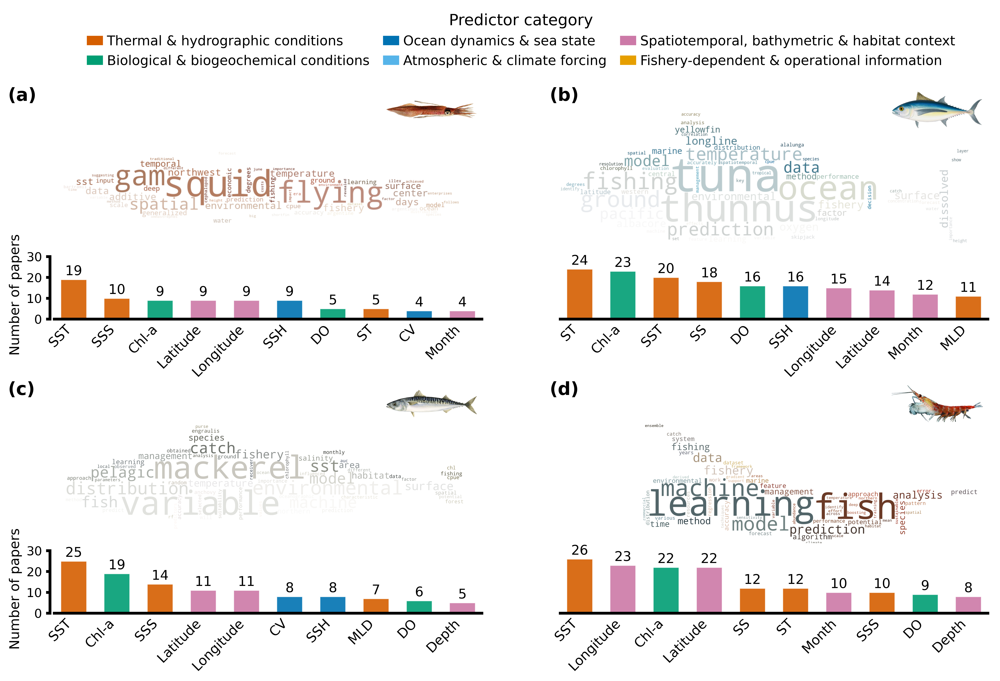

In [7]:
# Draw Figure 6 word clouds and group-specific predictor rankings
OUTPUT_WORDCLOUD = FIGURE_DIR / 'Fig_06.png'
OUTPUT_WORDCLOUD_PDF = FIGURE_DIR / 'Fig_06.pdf'
PREDICTOR_CATEGORY_CSV_FIG6 = DATA_DIR / 'Predictor_category.csv'
FIG6_CATEGORY_ORDER = PREDICTOR_CATEGORY_ORDER
FIG6_CATEGORY_COLORS = PREDICTOR_CATEGORY_COLORS


squid_mask = load_binary_mask('./figure/fig_element/Squid_O.bartramii_mask.png', use_alpha=True)
tuna_mask = load_binary_mask('./figure/fig_element/Tuna_T.alalungamask.png', use_alpha=True)
sp_mask = load_binary_mask('./figure/fig_element/Small-pelagics_S.scombrus_mask.png', use_alpha=True)
other_mask = load_binary_mask('./figure/fig_element/Other-species_Krill_mask.png', use_alpha=True)

# Paper-level Top-10 predictor rankings and a shared y scale for comparison.
group_top_predictors = {}
fig6_tie_priority = {
    ('Other Species', 'SST'): 0,
    ('Other Species', 'Longitude'): 1,
}
for group in FOCUS_GROUPS:
    group_mask = df['Fish_Group_list'].apply(lambda groups: group in groups)
    predictor_counts = {}
    for predictor_cell in df.loc[group_mask, 'Predictor']:
        for predictor in set(split_multivalue(predictor_cell)):
            predictor_counts[predictor] = predictor_counts.get(predictor, 0) + 1
    group_top_predictors[group] = sorted(
        predictor_counts.items(),
        key=lambda item: (
            -item[1],
            fig6_tie_priority.get((group, item[0]), 2),
            item[0].casefold(),
        ),
    )[:10]
fig6_predictor_max = max(
    count for ranking in group_top_predictors.values() for _, count in ranking
)
fig6_y_limit = int(np.ceil(fig6_predictor_max / 10) * 10)
predictor_category_table_fig6 = pd.read_csv(PREDICTOR_CATEGORY_CSV_FIG6)
if predictor_category_table_fig6['Predictor'].duplicated().any():
    raise ValueError('Duplicate predictors in Predictor_category.csv')
predictor_category_fig6 = predictor_category_table_fig6.set_index('Predictor')['Category'].to_dict()
displayed_predictors_fig6 = {
    predictor for ranking in group_top_predictors.values() for predictor, _ in ranking
}
missing_predictor_categories_fig6 = sorted(displayed_predictors_fig6 - set(predictor_category_fig6))
if missing_predictor_categories_fig6:
    raise ValueError(f'Missing Figure 6 predictor categories: {missing_predictor_categories_fig6}')

fig = plt.figure(figsize=(13, 8.6))
gs5 = fig.add_gridspec(
    4, 2, height_ratios=[3.0, 1.35, 3.0, 1.35],
    hspace=0.00, wspace=0.16, left=0.08, right=0.98, top=0.91, bottom=0.06
)
wordcloud_slots = [gs5[0, 0], gs5[0, 1], gs5[2, 0], gs5[2, 1]]
axes = [fig.add_subplot(slot) for slot in wordcloud_slots]
footer_axes = [fig.add_subplot(gs5[1, 0]), fig.add_subplot(gs5[1, 1]),
               fig.add_subplot(gs5[3, 0]), fig.add_subplot(gs5[3, 1])]

for idx, group in enumerate(FOCUS_GROUPS):
    word_freq = group_word_frequencies[group]

    if group == 'Squid':
        mask = squid_mask
        color_path = './figure/fig_element/Squid_O.bartramii.png'
    elif group == 'Tuna':
        mask = tuna_mask
        color_path = './figure/fig_element/Tuna_T.alalunga.png'
    elif group == 'Small Pelagics':
        mask = sp_mask
        color_path = './figure/fig_element/Small-pelagics_S.scombrus.png'
    else:
        mask = other_mask
        color_path = './figure/fig_element/Other-species_Krill.png'
    
    wc = WordCloud(
        mask=mask,
        background_color='white',
        stopwords=FIG6_STOPWORDS,
        max_words=60,
        colormap='viridis',
        random_state=42,
        collocations=False,
        min_word_length=3,
    ).generate_from_frequencies(word_freq)
    
    color_img = np.array(Image.open(color_path))
    image_colors = ImageColorGenerator(color_img)
    wc.recolor(color_func=image_colors)
    
    top_predictors = group_top_predictors[group]

    ax = axes[idx]
    ax.imshow(wc, interpolation='bilinear')
    # Anchor logos to the fixed GridSpec cell rather than the image-adjusted
    # word-cloud axes so positions align exactly across rows and columns.
    logo_slot = wordcloud_slots[idx].get_position(fig)
    logo_width = logo_slot.width * 0.21
    logo_height = logo_slot.height * 0.19
    logo_ax = fig.add_axes([logo_slot.x1 - logo_width - logo_slot.width * 0.02,
                            logo_slot.y1 - logo_height - logo_slot.height * 0.03,
                            logo_width, logo_height])
    logo_ax.imshow(color_img, interpolation='bilinear')
    logo_ax.axis('off')
    logo_ax.patch.set_alpha(0)
    ax.axis('off')
    footer_ax = footer_axes[idx]
    predictor_names = [name for name, _ in top_predictors]
    predictor_values = np.array([count for _, count in top_predictors])
    x_positions = np.arange(len(top_predictors))
    predictor_bar_colors = [
        FIG6_CATEGORY_COLORS[predictor_category_fig6[predictor]]
        for predictor in predictor_names
    ]
    footer_ax.bar(x_positions, predictor_values, width=0.60,
                  color=predictor_bar_colors, edgecolor='white', linewidth=0.8,
                  alpha=0.9)
    footer_ax.set_xlim(-0.55, len(top_predictors) - 0.45)
    footer_ax.set_ylim(-fig6_y_limit * 0.34, fig6_y_limit * 1.12)
    for x, name, value in zip(x_positions, predictor_names, predictor_values):
        footer_ax.text(x, value + fig6_y_limit * 0.025, str(int(value)),
                       ha='center', va='bottom', fontsize=12)
        footer_ax.text(x, -fig6_y_limit * 0.055, name,
                       ha='right', va='top', rotation=45, fontsize=12)
    footer_ax.set_xticks([])
    if idx % 2 == 0:
        footer_ax.set_yticks(np.arange(0, fig6_y_limit + 1, 10))
        footer_ax.set_ylabel('Number of papers', fontsize=12)
        footer_ax.tick_params(axis='y', width=2.5, labelsize=11)
        footer_ax.spines['left'].set_linewidth(2.5)
        footer_ax.spines['left'].set_bounds(0, fig6_y_limit)
    else:
        footer_ax.set_yticks([])
        footer_ax.set_ylabel('')
        footer_ax.spines['left'].set_visible(False)
    footer_ax.spines['top'].set_visible(False)
    footer_ax.spines['right'].set_visible(False)
    footer_ax.spines['bottom'].set_linewidth(2.5)
    footer_ax.spines['bottom'].set_position(('data', 0))
    footer_ax.spines['bottom'].set_bounds(-0.45, len(top_predictors) - 0.55)

fig6_legend_handles = [
    Patch(facecolor=FIG6_CATEGORY_COLORS[category], edgecolor='none', label=category)
    for category in FIG6_CATEGORY_ORDER
]
fig.legend(
    handles=fig6_legend_handles, title='Predictor category',
    loc='upper center', bbox_to_anchor=(0.53, 1.03), ncol=3,
    frameon=False, fontsize=12, title_fontsize=14,
    columnspacing=1.0, handlelength=1.2, handletextpad=0.3,
)

# Use GridSpec-cell coordinates rather than image-adjusted axes coordinates
# so panel labels align exactly by row and column despite differing masks.
for idx, slot in enumerate(wordcloud_slots):
    slot_box = slot.get_position(fig)
    label_x = slot_box.x0 - 0.04 if idx % 2 == 0 else slot_box.x0 - 0.006
    fig.text(label_x, slot_box.y1 - 0.004,
             f'({chr(97 + idx)})', fontsize=16, fontweight='bold',
             va='top', ha='left')

# Move the compact bar panels upward into the unused lower margin of each
# word-cloud panel, reducing the visible gap without changing either plot.
for footer_ax in footer_axes:
    footer_position = footer_ax.get_position()
    footer_ax.set_position([footer_position.x0, footer_position.y0 + 0.055,
                            footer_position.width, footer_position.height])

fig.savefig(OUTPUT_WORDCLOUD_PDF, bbox_inches='tight', facecolor='white', edgecolor='none')
fig.savefig(OUTPUT_WORDCLOUD, dpi=600, bbox_inches='tight', facecolor='white', edgecolor='none')
plt.close(fig)
display(IPythonImage(filename=str(OUTPUT_WORDCLOUD), width=900))